<a href="https://colab.research.google.com/github/andreswSilva/colab_AD05/blob/main/desafio_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![title](https://ik.imagekit.io/vzr6ryejm/colab/jupyter_notebook-API.drawio.png)

# 🐶 vs 🐱 Versão 3: galeria "Cachorros vs Gatos"

Baixa várias imagens de cada animal, com nomes diferentes, e gera uma página `galeria.html` com duas colunas lado a lado.

No Colab, a galeria é exibida direto no notebook e pode ser baixada em um `.zip` pronto para abrir no navegador.

> No Colab os arquivos ficam em `/content` e **são apagados quando a sessão termina**. Baixe o que quiser guardar pelo painel de arquivos (ícone de pasta, à esquerda).

> ✍️ **Atenção:** algumas linhas estão incompletas. Substitua cada `___` para completar o código, nas linhas marcadas com `# complete esta linha`.

## 1. Configuração

In [1]:
import os
import requests

QUANTIDADE = 6  # quantas imagens de cada animal

base = os.getcwd()
pasta = os.path.join(base, 'imagens/galeria')
os.makedirs(pasta, exist_ok=True)

## 2. Função para baixar e salvar

In [2]:
def salvar(img_url, nome):
    """Baixa a imagem, salva em imagens/galeria e devolve o nome do arquivo."""
    extensao = os.path.splitext(img_url)[1] or '.jpg'
    arquivo = nome + extensao
    img_data = requests.get(img_url).content
    with open(os.path.join(pasta, arquivo), 'wb') as handler:
        handler.write(img_data)
    print(f"Salvo: imagens/{arquivo}")
    return arquivo

## 3. Baixar cachorros e gatos

In [3]:
urls_caes = requests.get(
    f'https://dog.ceo/api/breeds/image/random/{QUANTIDADE}'  # complete esta linha
).json()['message']  # complete esta linha
caes = [salvar(u, f'dog_{i}') for i, u in enumerate(urls_caes, start= 1)]  # complete esta linha

urls_gatos = [
    item['url']  # complete esta linha
    for item in requests.get(
        f'https://api.thecatapi.com/v1/images/search?limits={QUANTIDADE}'  # complete esta linha
    ).json()
]
gatos = [salvar(u, f'cat_{i}') for i, u in enumerate(urls_gatos, start=1)]
 #esse foi mais facil :)

Salvo: imagens/dog_1.jpg
Salvo: imagens/dog_2.jpg
Salvo: imagens/dog_3.jpg
Salvo: imagens/dog_4.jpg
Salvo: imagens/dog_5.jpg
Salvo: imagens/dog_6.jpg
Salvo: imagens/cat_1.jpg


## 4. Gerar o HTML

A função `gerar_html` recebe uma função `src` que diz qual endereço usar em cada `<img>`. Assim o mesmo código gera a versão para download (caminhos relativos) e a versão para exibir no notebook (imagens embutidas).

In [4]:
def coluna(titulo, arquivos, src):
    imgs = '\n'.join(f'      <img src="{src(a)}" alt="{a}">' for a in arquivos)
    return f"""    <section>
      <h2>{titulo}</h2>
{imgs}
    </section>"""


def gerar_html(src):
    return f"""<!DOCTYPE html>
<html lang="pt-BR">
<head>
  <meta charset="utf-8">
  <title>Cachorros vs Gatos</title>
  <style>
    body {{ font-family: sans-serif; margin: 20px; background: #f5f5f5; }}
    h1 {{ text-align: center; color: #222; }}
    main {{ display: flex; gap: 20px; }}
    section {{ flex: 1; background: white; padding: 15px; border-radius: 10px; }}
    h2 {{ text-align: center; color: #222; }}
    img {{ width: 100%; margin-bottom: 10px; border-radius: 8px; }}
  </style>
</head>
<body>
  <h1>Cachorros vs Gatos</h1>
  <main>
{coluna('Cachorros', caes, src)}
{coluna('Gatos', gatos, src)}
  </main>
</body>
</html>
"""

## 5. Salvar `galeria.html`
Usa caminhos relativos (`imagens/galeria/...`), então funciona quando aberto ao lado da pasta `imagens/`.

In [ ]:
html = gerar_html(lambda a: f'imagens/galeria/{a}')

caminho_html = os.path.join(base, 'galeria.html')
with open(caminho_html, 'w', encoding='utf-8') as f:
    f.write(html)

print(f"Galeria criada: {caminho_html}")

Galeria criada: /content/galeria.html


## 6. Ver a galeria no notebook
O Colab exibe a saída dentro de um iframe, que não enxerga os arquivos da sessão. Por isso aqui as imagens são embutidas no próprio HTML (base64).


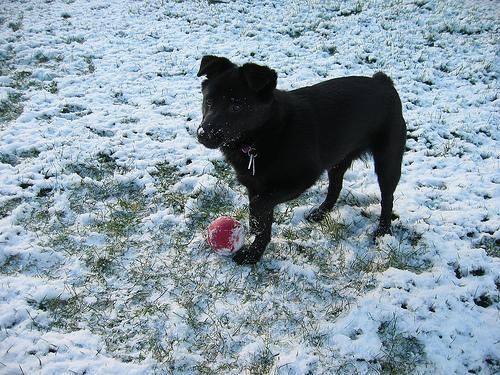
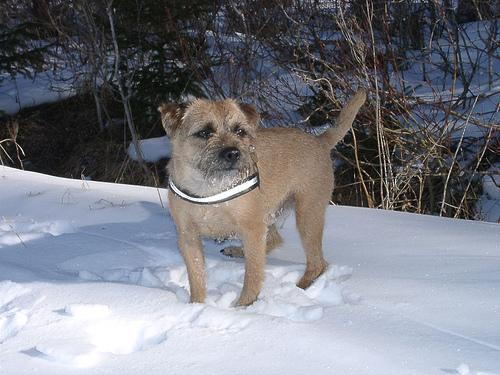
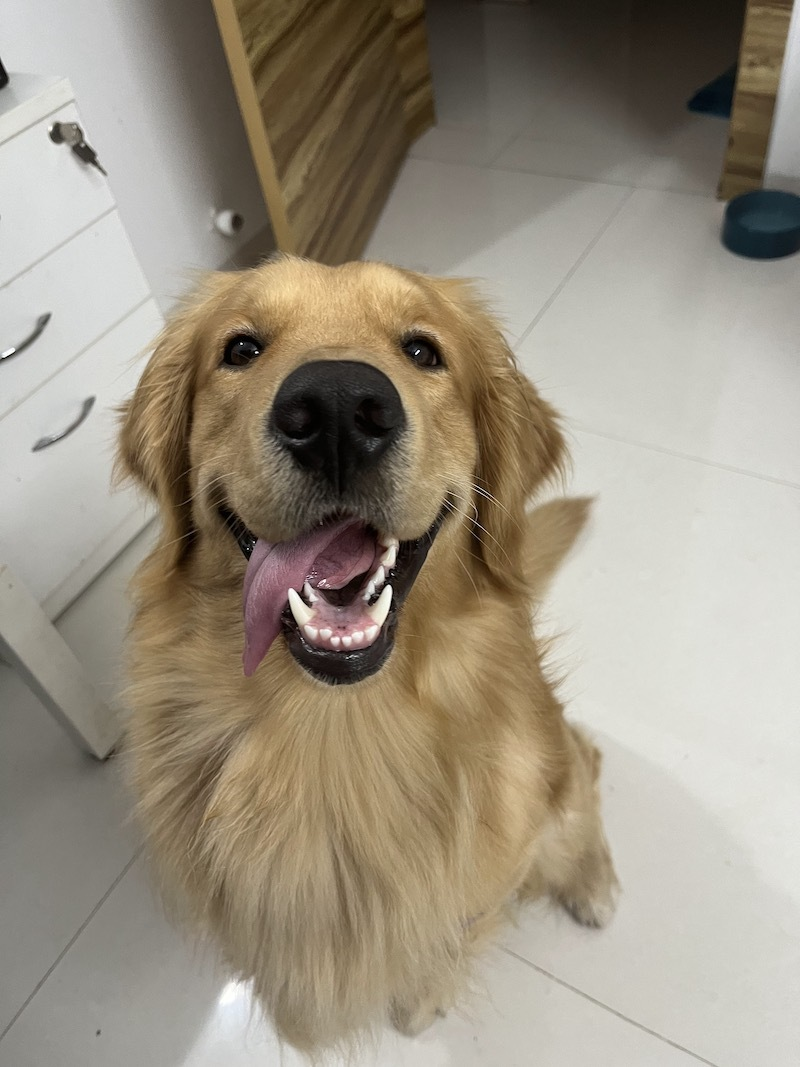
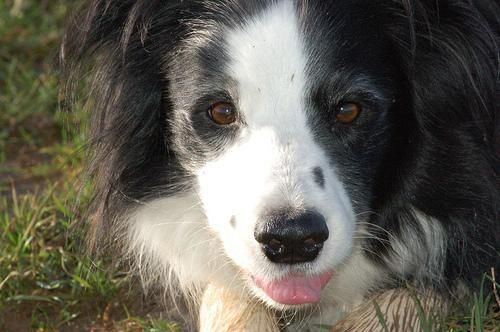
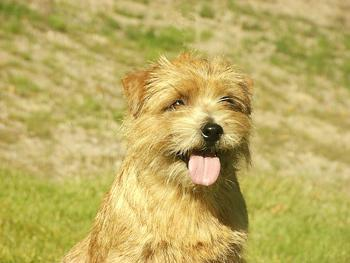
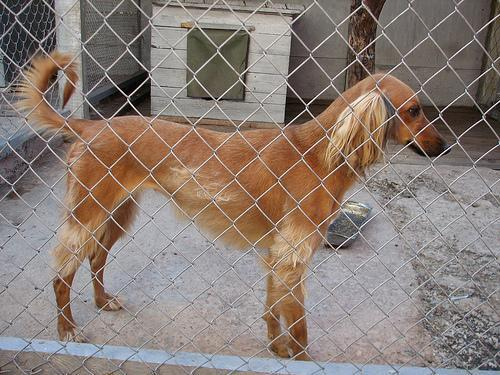
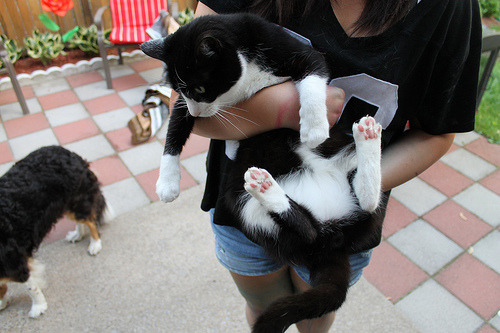
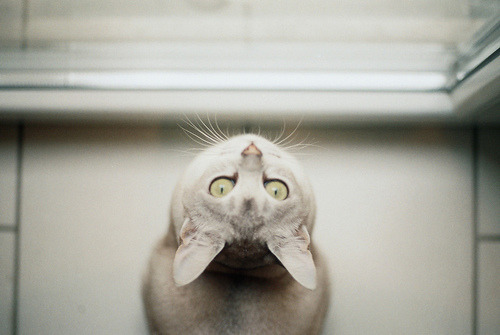
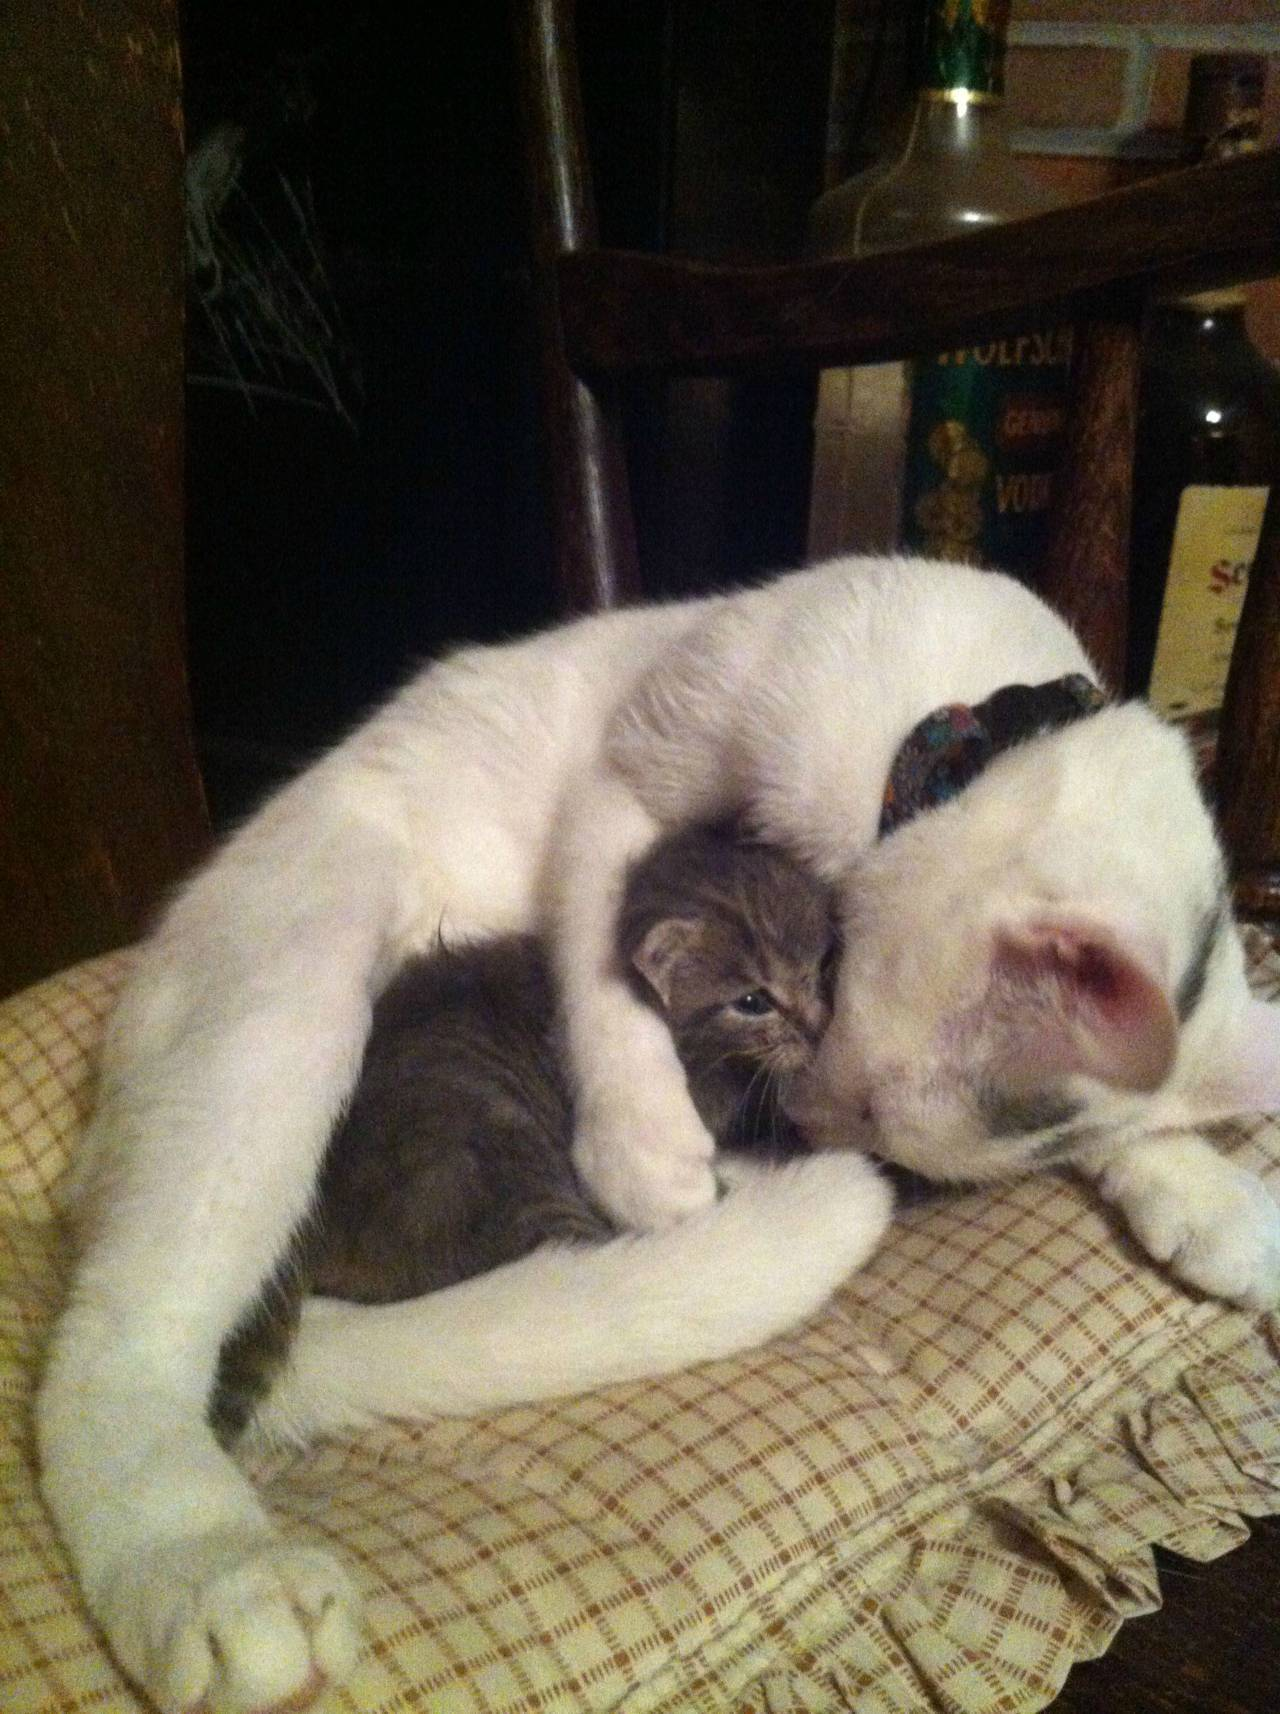
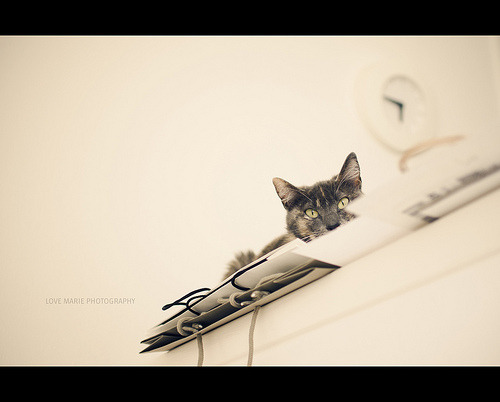
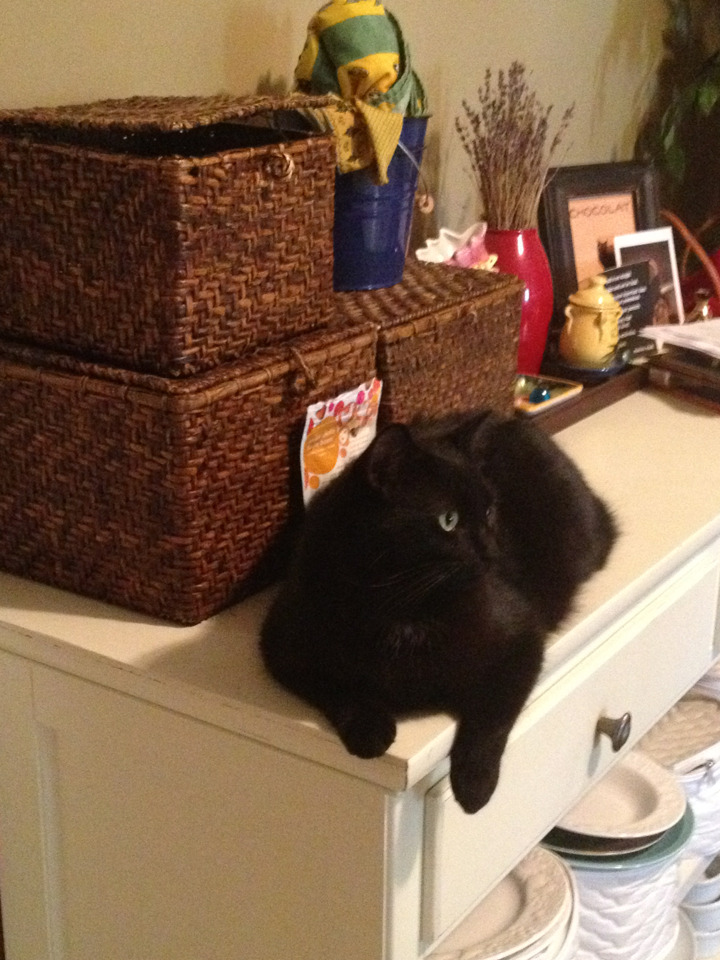
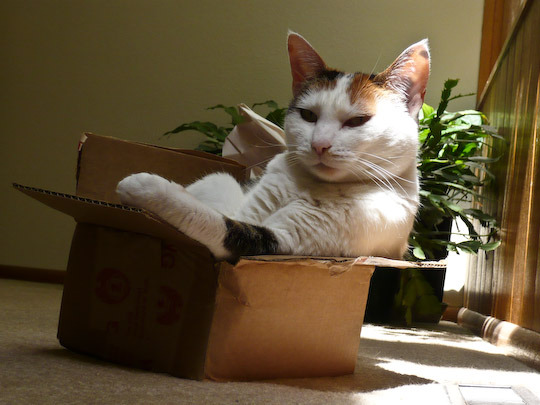

In [ ]:
import base64
from IPython.display import HTML, display

def embutir(arquivo):
    ext = os.path.splitext(arquivo)[1].lstrip('.').lower()
    mime = 'jpeg' if ext in ('jpg', 'jpeg') else ext
    with open(os.path.join(pasta, arquivo), 'rb') as f:
        dados = base64.b64encode(f.read()).decode()
    return f'data:image/{mime};base64,{dados}'

display(HTML(gerar_html(embutir)))

## 7. Baixar a galeria para o seu computador
Gera um `.zip` com o `galeria.html` e a pasta `imagens/`. Depois de extrair, abra o `galeria.html` no navegador.

In [ ]:
import zipfile
with zipfile.ZipFile('galeria.zip', 'w') as z:
    z.write('galeria.html')
    for a in caes + gatos:
        z.write(os.path.join('imagens/galeria', a))

try:
    from google.colab import files
    files.download('galeria.zip')
except ImportError:
    print("Fora do Colab: o arquivo galeria.zip foi criado na pasta atual.")